In [1]:
### 0) Setup and Imports

import pandas as pd
import numpy as np
import os
import geopandas as gpd
from shapely.geometry import Point, box, LineString
from shapely.ops import linemerge
import matplotlib.pyplot as plt


In [2]:
### 1) Import CSV Ecohydro Data
# currently desired data is in complete_data.csv

# Keep spatial data in feet for HWRC stakeholders:
complete_data_25 = pd.read_csv("data/25_ecohydroData.csv")
print(complete_data_25.columns)
complete_data_26 = pd.read_csv("data/26_ecohydroData.csv")
print(complete_data_26.columns)

# Combine the 2 years of data into one csv by matching columns and appending the data
complete_data = pd.concat([complete_data_25, complete_data_26], ignore_index=True)
print("Total points in complete_data from 2025: ", len(complete_data_25))
print("Total points in complete_data from 2026: ", len(complete_data_26))
print("Total points in complete_data: ", len(complete_data))

Index(['Collection Date', 'Collection Time', 'Northing', 'Easting',
       'Elevation', 'Longitude', 'Latitude', 'Global_ID_Eco', 'Type',
       'Transect ID', 'Section', 'Measurement Point ID', 'Reading Number',
       'Total water depth', 'Depth', 'Actual depth', 'Velocity', 'Velocity 2',
       'Point Notes', 'SMB Presence', 'Bank Measurement Began',
       'Investigators'],
      dtype='object')
Index(['Collection Date', 'Collection Time', 'Northing', 'Easting',
       'Elevation', 'Longitude', 'Latitude', 'Global_ID_Eco', 'Type',
       'Transect ID', 'Section', 'Measurement Point ID', 'Reading Number',
       'Total water depth', 'Depth', 'Velocity', 'Depth 2', 'Velocity 2',
       'Point Notes', 'SMB Presence', 'Bank Measurement Began',
       'Investigators'],
      dtype='object')
Total points in complete_data from 2025:  1195
Total points in complete_data from 2026:  2363
Total points in complete_data:  3558


In [3]:
### Sort the data into separate csvs based on their northing column value
# currently desired data is in complete_data_{Section} df

# Assign "Section" based on northing value that was made based on observation of data
# One transect at North Territorial is removed; it's too far North of Middle section
complete_data.loc[complete_data['Northing'] > 340000, 'Section'] = 'Upper'
complete_data.loc[
    (complete_data['Northing'] <= 323000) & (complete_data['Northing'] >= 280000), 'Section'
] = 'Middle'
complete_data.loc[complete_data['Northing'] < 255000, 'Section'] = 'Lower'

# Treat blank (NaN or empty string) values in the Section column as "Middle"
complete_data['Section'] = complete_data['Section'].replace('', np.nan)
complete_data['Section'] = complete_data['Section'].fillna('Middle')

# Create a separate DataFrame for each section
complete_data_Upper = complete_data[complete_data['Section'] == 'Upper'].copy()
complete_data_Middle = complete_data[complete_data['Section'] == 'Middle'].copy()
complete_data_Lower = complete_data[complete_data['Section'] == 'Lower'].copy()

print(f"Rows in complete_data_Upper.csv: {len(complete_data_Upper)}")
print(f"Rows in complete_data_Middle.csv: {len(complete_data_Middle)}")
print(f"Rows in complete_data_Lower.csv: {len(complete_data_Lower)}")

Rows in complete_data_Upper.csv: 1168
Rows in complete_data_Middle.csv: 1703
Rows in complete_data_Lower.csv: 687


In [4]:
### 2) Import Upstream Depth FOR EACH SECTION (next 2 cells as well)
# currently desired data is in complete_data_{Section} df

# 2a) Middle Section

# Read in the depth
depth_data_mm_25 = pd.read_csv('data/25_depthSensorData_Middle.csv', skiprows=3)
depth_data_mm_26 = pd.read_csv('data/26_depthSensorData_Middle.csv', skiprows=3)

# Combine the 2 years of data into one csv by appending the csvs
depth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')

# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
#print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet (both years already combined above)
# manual inputs are from field observations to convert the sensor output into elevation values
depth_agg_final = ((7313.2 - depth_agg_trimmed) * 0.00328084).sort_index()
print(f'Depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
complete_data_Middle['Collection Date'] = pd.to_datetime(
    complete_data_Middle['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching since trend timescale is daily
complete_data_Middle['Date'] = complete_data_Middle['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
depth_daily_Middle = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data_Middle['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data_Middle.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily_Middle:
        complete_data_Middle.at[idx, 'upstream_depth'] = depth_daily_Middle[obs_date]

# Clean up temporary Date column since matching is done
complete_data_Middle = complete_data_Middle.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data_Middle: {len(complete_data_Middle)}")
print(f"Points with upstream depth data: {complete_data_Middle['upstream_depth'].notna().sum()}")

Depth resampling successful
Depth series: 1288 points (2025-05-30 to 2026-09-01)

Data matching summary:
Total points in complete_data_Middle: 1703
Points with upstream depth data: 1691


In [5]:
# 2b) Upper Section
# currently desired data is in complete_data_{Section} df

# Read in the depth
depth_data_mm = pd.read_csv('data/26_depthSensorData_Upper.csv', skiprows=3)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')

# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet (both years already combined above)
upper_offset = 1587.50
depth_agg_final = ((upper_offset - depth_agg_trimmed) * 0.00328084).sort_index()  ### FINAL
print(f'Depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
# format='mixed' parses each value individually, handling native Excel datetimes,
# M/D/YYYY text dates (e.g. "6/6/2026"), and dates with times (e.g. "6/6/2025 16:00")
# dayfirst=False ensures M/D/YYYY (month-first) interpretation
complete_data_Upper['Collection Date'] = pd.to_datetime(
    complete_data_Upper['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching
# Note: depth_agg_final already have DatetimeIndex
complete_data_Upper['Date'] = complete_data_Upper['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
# (Upper-specific name so each section keeps its own daily depth lookup)
depth_daily_Upper = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data_Upper['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data_Upper.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily_Upper:
        complete_data_Upper.at[idx, 'upstream_depth'] = depth_daily_Upper[obs_date]

# Clean up temporary Date column
complete_data_Upper = complete_data_Upper.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data_Upper: {len(complete_data_Upper)}")
print(f"Points with upstream depth data: {complete_data_Upper['upstream_depth'].notna().sum()}")

Depth resampling successful
Size of depth_agg: (884,)
Depth series: 835 points (2026-03-01 to 2026-09-02)

Data matching summary:
Total points in complete_data_Upper: 1168
Points with upstream depth data: 1168


In [6]:
# 2c) Lower Section
# currently desired data is in complete_data_{Section} df

# Read in the depth
depth_data_mm_25 = pd.read_csv('data/25_depthSensorData_Lower.csv', skiprows=3)
depth_data_mm_26 = pd.read_csv('data/26_depthSensorData_Lower.csv', skiprows=3)

# Combine the 2 years of data into one csv by appending the csvs
depth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')
# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet (both years already combined above)
lower_offset = 6705.6
depth_agg_final = ((lower_offset - depth_agg_trimmed) * 0.00328084).sort_index()  ### FINAL
print(f'Depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
# format='mixed' parses each value individually, handling native Excel datetimes,
# M/D/YYYY text dates (e.g. "6/6/2026"), and dates with times (e.g. "6/6/2025 16:00")
# dayfirst=False ensures M/D/YYYY (month-first) interpretation
complete_data_Lower['Collection Date'] = pd.to_datetime(
    complete_data_Lower['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching
# Note: depth_agg_final already have DatetimeIndex
complete_data_Lower['Date'] = complete_data_Lower['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
# (Lower-specific name so each section keeps its own daily depth lookup)
depth_daily_Lower = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data_Lower['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data_Lower.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily_Lower:
        complete_data_Lower.at[idx, 'upstream_depth'] = depth_daily_Lower[obs_date]

# Clean up temporary Date column
complete_data_Lower = complete_data_Lower.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data_Lower: {len(complete_data_Lower)}")
print(f"Points with upstream depth data: {complete_data_Lower['upstream_depth'].notna().sum()}")


Depth resampling successful
Size of depth_agg: (1421,)
Depth series: 1375 points (2025-06-05 to 2026-09-01)

Data matching summary:
Total points in complete_data_Lower: 687
Points with upstream depth data: 687


In [7]:
### 3) ADCP Velocity upload and merge
# currently desired data is in complete_data_{Section} df

# Read in the velocity
sontek_data = pd.read_csv('data/25_ADCPData.csv', skiprows=3)

# Convert datetime columns to pandas datetime and set as index for resampling
sontek_data['_time'] = pd.to_datetime(sontek_data['_time'])
sontek_data = sontek_data.set_index('_time')

# Aggregate sontek velocity data
sontek_interval_minutes = 300
sontek_agg = sontek_data['_value'].resample(f'{sontek_interval_minutes}min').median()
print('Sontek resampling successful')

# Remove NaN values from aggregation
sontek_agg = sontek_agg.dropna()
#print(f'Aggregated data shape: {sontek_agg.shape}')

# Sontek outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
sontek_mean = sontek_agg.mean()
sontek_std = sontek_agg.std()
sontek_mask = np.abs(sontek_agg - sontek_mean) <= outlier_std_threshold * sontek_std
sontek_agg_final = sontek_agg[sontek_mask]

# Convert ADCP velocity from m/s to ft/s so it matches complete_data
M_TO_FT = 1.0 / 0.3048
sontek_agg_final = sontek_agg_final * M_TO_FT

# Create a DataFrame from the aggregated sontek velocity data
# The ADCP sensor is located in the Middle section, so tag it accordingly
sontek_df = pd.DataFrame({
    'Collection Date': sontek_agg_final.index,   # _time from velocity data
    'Velocity': sontek_agg_final.values,         # aggregated velocity (ft/s)
    'Depth': 1,                                  # set Depth to 1 for all velocity points
    'Northing': 319995.5,                        # constant Northing for sontek location
    'Easting': 13244857,                         # constant Easting for sontek location
    'Type': 'Sontek',                            # add Type column for plotting model dependencies
    'Section': 'Middle'                          # ADCP data belongs to the Middle section
})

# Match upstream_depth for sontek data based on date (using the Middle section's daily depths)
sontek_df['upstream_depth'] = sontek_df['Collection Date'].apply(
    lambda dt: depth_daily_Middle.get(dt.date(), np.nan)
)
#print(f"Sontek points with upstream_depth matched: {sontek_df['upstream_depth'].notna().sum()} / {len(sontek_df)}")

# Append the sontek velocity data to complete_data_Middle
complete_data_Middle = pd.concat([complete_data_Middle, sontek_df], ignore_index=True)

# Print summary of added data points
print(f"\nSontek velocity data appended to complete_data_Middle")
print(f"  Points added: {len(sontek_df)}")
print(f"  New total rows in complete_data_Middle: {len(complete_data_Middle)}")

Sontek resampling successful

Sontek velocity data appended to complete_data_Middle
  Points added: 475
  New total rows in complete_data_Middle: 2178


In [8]:
### 4) One velocity per survey point, transferred to a common height above the bed
# =============================================================================
#
# WHY THIS REPLACES A FILTER
#   Each survey point was measured at several heights above the bed, and the 2-D
#   model needs one velocity per point. Keeping only the readings taken at exactly
#   one height throws away every point that was not sampled there. Instead the
#   readings are transferred to a common height.
#
# THE TRANSFER: a one-stage logarithmic profile
#
#       v(h) = v(z) * ln(h / z_p) / ln(z / z_p)
#
#   z_p is the PROFILE SCALE PARAMETER: one fitted constant per section, the height
#   at which the fitted logarithmic curve extrapolates to zero velocity.
#
#   *** z_p IS NOT A BED ROUGHNESS LENGTH. *** It is named z_p, not z0, to keep that
#   clear. Three things rule out the roughness reading, all measured from this data:
#     - Fitted per substrate class it runs BACKWARDS: 27.7 mm on silt and muck,
#       14.5 mm on sand, 8.9 mm on gravel. Roughness must rise with grain size.
#       It is tracking hydraulic setting, since fine material settles in slow pools
#       and gravel is exposed in fast riffles.
#     - Where the notes state a grain size, the grain-based value (k_s/30 with
#       k_s ~ 2.5d) is 0.6 to 2.9 mm. The fit gives 3 to 14 times more, consistent
#       with form drag from bedforms, vegetation and woody debris.
#     - It lands far below the shallowest measurement, so nothing in the survey
#       constrains it directly.
#   Shear velocity is never needed: it cancels in the ratio, and each point is
#   anchored on its own measured reading.
#
# READINGS BELOW FIT_MIN_HEIGHT_FT ARE NOT USED
#   The near-bed layer is where a profile law is not expected to hold. Readings
#   below the cutoff are excluded from the fit AND from use as a transfer source,
#   so the law is never applied outside the range it was fitted on. In open-channel
#   flow the logarithmic region reaches roughly half the flow depth, and this cutoff
#   sits at about a fifth to a quarter of it, so the retained data lie inside that
#   region.
#
# UNITS
#   "Depth" is the height above the bed in FEET, so the settings below are in feet.
#   Output is in the same units as "Velocity" (ft/s) - convert to SI later, in the
#   model notebook, exactly as "Velocity" already is.
#
# WHAT IT ADDS  (names come from VEL_COLUMN)
#   vel_1     the velocity at TARGET_HEIGHT_FT above the bed
#   vel_1_sd  how uncertain that number is: 0 where it was measured directly, the
#              section's measured transfer error where it was converted. Pass it to
#              the GP as a per-point `alpha` so a converted value is not trusted
#              like a measured one.
#
#   One row survives per survey VISIT (the reading closest to the target height),
#   not per latitude/longitude. Occupying the same coordinates on a later day is
#   a new observation and is kept. The ADCP/Sontek series, all at one lat/lon,
#   is kept in full - each timestamp is its own visit.
#
# USES ONLY THE LIBRARIES ALREADY IMPORTED IN CELL 0 (pandas as pd, numpy as np)
# =============================================================================

# ------------------------------ SETTINGS -------------------------------------
TARGET_HEIGHT_FT  = 1.0      # height above the bed that every reading is moved to
FIT_MIN_HEIGHT_FT = 0.5      # ignore readings below this, for fitting and as sources
VEL_COLUMN        = 'vel_1'  # output column name, matching TARGET_HEIGHT_FT above -
                             # rename both together if the target height changes
MEASURED_ONLY     = ['Middle', 'Upper', 'Lower']  # keep ONLY direct 1 ft measurements.
                             # Converted (log-law) points are discarded so every
                             # row used for model training was measured at 1 ft.
Z_P_BOUNDS_FT     = (1e-4, 0.30)   # search range for the profile scale parameter
Z_P_STEPS         = 60       # points in the log-spaced search
MIN_LEVELS        = 2        # heights a point needs before it can inform the shape
POINT_KEY         = ['Collection Date', 'Measurement Point ID']   # one survey VISIT
                             # (day + point id). Same lat/lon on a different day
                             # is a different visit and is not collapsed.

print('=' * 74)
print(f'VELOCITY TRANSFERRED TO {TARGET_HEIGHT_FT} ft ABOVE THE BED  ->  "{VEL_COLUMN}"')
print(f'one-stage log profile, fitted on readings at or above {FIT_MIN_HEIGHT_FT} ft')
print('=' * 74)


def _shape(z, z_p):
    """log of the log-profile shape. The per-point scale is an additive constant
    here, which is why it drops out of both the fit and the transfer."""
    return np.log(np.log(z / z_p))


def _fit_profile_scale(df):
    """Search z_p for the best within-point fit of the logarithmic profile.

    Each point's mean log-velocity and mean shape are removed before scoring, so
    z_p is chosen on the SHAPE of the profiles only and is not pulled around by how
    fast or slow individual locations are.

    Returns z_p, the number of points used, the fraction of within-point variation
    explained, and the range of z_p values that score within 2% of the best.
    """
    q = df[(df['Velocity'] > 0) & (df['Depth'] >= FIT_MIN_HEIGHT_FT)].copy()
    q = q[q.groupby(q['_pt'])['Depth'].transform('nunique') >= MIN_LEVELS]
    if q['_pt'].nunique() < 10:
        return np.nan, 0, np.nan, (np.nan, np.nan)

    lv = np.log(q['Velocity'].values)
    grp = q['_pt'].values
    lv_c = lv - pd.Series(lv).groupby(grp).transform('mean').values
    z = q['Depth'].values

    lo, hi = Z_P_BOUNDS_FT
    hi = min(hi, 0.9 * z.min())                 # z_p must stay below every reading
    if not (hi > lo):
        return np.nan, 0, np.nan, (np.nan, np.nan)

    scores = []
    for z_p in np.logspace(np.log10(lo), np.log10(hi), Z_P_STEPS):
        F = _shape(z, z_p)
        F_c = F - pd.Series(F).groupby(grp).transform('mean').values
        # The shape enters with a coefficient of exactly ONE: v = A * ln(z/z_p)
        # becomes log v = log A + log(ln(z/z_p)), and log A is the per-point offset
        # already removed by centring. Letting a coefficient float here would trade
        # off against z_p and leave both unidentified.
        scores.append((np.sum((lv_c - F_c) ** 2), z_p))
    if not scores:
        return np.nan, 0, np.nan, (np.nan, np.nan)

    sse, z_p = min(scores, key=lambda t: t[0])
    total = np.sum(lv_c ** 2)
    r2 = 1.0 - sse / max(total, 1e-12)
    band = [zp for sc, zp in scores if sc <= sse * 1.02]
    at_bound = (z_p <= lo * 1.01) or (z_p >= hi * 0.99)
    if at_bound:
        print(f'  WARNING: z_p ran to the edge of Z_P_BOUNDS_FT - widen the range '
              f'or treat the value as unidentified')
    return z_p, q['_pt'].nunique(), r2, (min(band), max(band))


def _transfer(heights, speeds, z_p, target):
    """Move a point's reading to `target` height using the fitted log profile.

    Only the reading closest to the target is used, and only readings at or above
    FIT_MIN_HEIGHT_FT qualify. Averaging all of a point's readings was tested and is
    clearly worse - a reading far away says much less about the target than a near
    one, and averaging lets the distant ones drag the answer. Ties are averaged.

    A reading of exactly zero cannot be logged, so zeros are set aside; if every
    qualifying reading is zero the answer is zero, which is right - still water at
    one height is still water at another.
    """
    heights = np.asarray(heights, dtype=float)
    speeds = np.asarray(speeds, dtype=float)
    ok = (np.isfinite(heights) & np.isfinite(speeds) & (speeds >= 0)
          & (heights >= FIT_MIN_HEIGHT_FT))
    heights, speeds = heights[ok], speeds[ok]
    if len(heights) == 0:
        return np.nan
    moving = speeds > 0
    if not moving.any():
        return 0.0
    heights, speeds = heights[moving], speeds[moving]
    gap = np.abs(np.log(heights) - np.log(target))
    closest = gap == gap.min()
    moved = (np.log(speeds[closest])
             + _shape(np.full(closest.sum(), target), z_p) - _shape(heights[closest], z_p))
    return float(np.exp(moved.mean()))


def _visit_id(df):
    """One id per survey visit, never per lat/lon alone.

    Multi-height readings at the same Measurement Point ID on the same calendar
    day collapse to one visit. The same coordinates occupied on a later day stay
    separate. Rows with no Measurement Point ID (ADCP/Sontek at a fixed lat/lon)
    are keyed by their full timestamp so repeats across days and times are kept.
    """
    collected = pd.to_datetime(df['Collection Date'], errors='coerce')
    survey_day = collected.dt.strftime('%Y-%m-%d')
    mpid = df['Measurement Point ID']
    has_mpid = mpid.notna() & mpid.astype(str).str.strip().ne('') & mpid.astype(str).ne('nan')
    is_fixed_location_series = (
        ~has_mpid
        | (df['Type'].astype(str).eq('Sontek') if 'Type' in df.columns
           else pd.Series(False, index=df.index))
    )
    key = survey_day + '|' + mpid.astype(str)
    return key.where(~is_fixed_location_series,
                     collected.astype(str) + '|ts|' + df.index.astype(str))


complete_data_by_section = {'Middle': complete_data_Middle,
                            'Upper':  complete_data_Upper,
                            'Lower':  complete_data_Lower}
trimmed_by_section = {}

for section_name, raw in complete_data_by_section.items():
    print(f'\n{section_name}')
    print('-' * 74)
    print(f'  starting rows: {len(raw)}')

    # --- rows that describe a velocity measured at a height ------------------
    # Do not require Measurement Point ID: the ADCP/Sontek series has none, but
    # those rows are repeat visits to one lat/lon and must be kept.
    work = raw.dropna(subset=['Velocity', 'Depth']).copy()
    work = work[work['Depth'] > 0]
    print(f'  rows with a velocity at a known height: {len(work)}')

    # --- the velocity >= 0 filter, kept from the previous version -------------
    before = len(work)
    work = work[work['Velocity'] >= 0]
    print(f'  after velocity >= 0 filter: {len(work)} (removed {before - len(work)})')

    work['_pt'] = _visit_id(work)
    usable = work[work['Depth'] >= FIT_MIN_HEIGHT_FT]
    print(f'  survey visits: {work["_pt"].nunique()}  '
          f'({usable["_pt"].nunique()} have a reading at or above {FIT_MIN_HEIGHT_FT} ft; '
          f'{work["_pt"].nunique() - usable["_pt"].nunique()} do not and are dropped)')
    print('  grouping is by survey day + point id, not by lat/lon - '
          'repeat occupations of the same location on a later day are kept')

    # --- 1. the profile scale parameter, fitted on this section's own profiles
    z_p, n_shape_pts, shape_r2, band = _fit_profile_scale(work)
    if not np.isfinite(z_p):
        print('  NOT ENOUGH multi-height points above the cutoff to fit the profile '
              '- section skipped'); continue
    FT_TO_MM = 304.8
    print(f'  profile scale z_p = {z_p:.5f} ft ({z_p*FT_TO_MM:.1f} mm), fitted on '
          f'{n_shape_pts} points measured at {MIN_LEVELS}+ heights above the cutoff')
    print(f'      explains {100*shape_r2:.0f}% of the within-point variation; values from '
          f'{band[0]*FT_TO_MM:.1f} to {band[1]*FT_TO_MM:.1f} mm fit within 2% as well')
    print(f'      report this as a fitted profile constant, NOT as a bed roughness')

    # --- 2. how wrong is a transferred value? measure it, do not assume -------
    # For every point measured AT the target height and also elsewhere above the
    # cutoff: hide the target reading, transfer the others to it, compare.
    errors, truths = [], []
    for _, g in work.groupby('_pt'):
        at_target = g[np.isclose(g['Depth'], TARGET_HEIGHT_FT)]
        others = g[~np.isclose(g['Depth'], TARGET_HEIGHT_FT)]
        if len(at_target) and len(others):
            guess = _transfer(others['Depth'], others['Velocity'], z_p, TARGET_HEIGHT_FT)
            if np.isfinite(guess):
                truth = at_target['Velocity'].mean()
                errors.append(guess - truth); truths.append(truth)
    transfer_sd = float(np.sqrt(np.mean(np.square(errors)))) if len(errors) >= 5 else np.nan
    if np.isfinite(transfer_sd):
        spread = float(np.std(truths)) if len(truths) > 1 else np.nan
        print(f'  transfer error: {transfer_sd:.3f} ft/s, measured on {len(errors)} '
              f'points sampled at the target height and elsewhere')
        print(f'      that is {transfer_sd/spread:.2f} of the spread of the thing being '
              f'predicted ({spread:.3f} ft/s); above ~0.8 a converted value would '
              f'carry little information')
    else:
        print(f'  transfer error: too few points to measure it - {VEL_COLUMN}_sd '
              f'left blank on converted points')

    # --- 3. one value per point ----------------------------------------------
    rows, n_measured, n_converted, n_too_shallow, n_no_source, n_skipped_conv = [], 0, 0, 0, 0, 0
    for _pt, g in work.groupby('_pt'):
        # ADCP/Sontek rows have no Total water depth; skip the median so an
        # all-NaN slice does not warn "Mean of empty slice"
        if 'Total water depth' in g.columns:
            water_vals = pd.to_numeric(g['Total water depth'], errors='coerce').to_numpy(dtype=float)
            finite_water = water_vals[np.isfinite(water_vals)]
            water = float(np.median(finite_water)) if finite_water.size else np.nan
        else:
            water = np.nan
        if np.isfinite(water) and water < TARGET_HEIGHT_FT:
            n_too_shallow += 1          # no water at that height - nothing to predict
            continue

        at_target = g[np.isclose(g['Depth'], TARGET_HEIGHT_FT)]
        if len(at_target):
            value, sd = float(at_target['Velocity'].mean()), 0.0
            n_measured += 1
        elif section_name in MEASURED_ONLY:
            n_skipped_conv += 1         # this section keeps measured values only
            continue
        else:
            value = _transfer(g['Depth'], g['Velocity'], z_p, TARGET_HEIGHT_FT)
            if not np.isfinite(value):
                n_no_source += 1        # every reading here is below the cutoff
                continue
            sd = transfer_sd
            n_converted += 1

        # keep the 1 ft reading as this point's row, so Depth is a real 1 ft
        # measurement and every other column is still from that visit
        keep = at_target.iloc[0].copy() if len(at_target) else (
            g.iloc[(g['Depth'] - TARGET_HEIGHT_FT).abs().values.argmin()].copy()
        )
        keep[VEL_COLUMN] = value
        keep[VEL_COLUMN + '_sd'] = sd
        keep['Depth'] = TARGET_HEIGHT_FT
        rows.append(keep)

    out = pd.DataFrame(rows).drop(columns=['_pt']).reset_index(drop=True)
    # Training data: only rows whose measurement depth is 1 ft
    n_before_depth = len(out)
    out = out[np.isclose(pd.to_numeric(out['Depth'], errors='coerce'), TARGET_HEIGHT_FT)].copy()
    out['Depth'] = TARGET_HEIGHT_FT
    n_not_1ft = n_before_depth - len(out)
    print(f'  {VEL_COLUMN} set on {len(out)} points: {n_measured} measured directly, '
          f'{n_converted} converted')
    print(f'  dropped, water shallower than {TARGET_HEIGHT_FT} ft: {n_too_shallow} points')
    print(f'  dropped, no reading at or above {FIT_MIN_HEIGHT_FT} ft to transfer from: '
          f'{n_no_source} points')
    if n_skipped_conv:
        print(f'  dropped, MEASURED_ONLY is set for this section: {n_skipped_conv} '
              f'points that would have been converted')
    if n_not_1ft:
        print(f'  dropped, measurement Depth was not {TARGET_HEIGHT_FT} ft: {n_not_1ft} points')
    n_xy = out.drop_duplicates(['Easting', 'Northing']).shape[0]
    n_repeat = len(out) - n_xy
    print(f'  unique Easting/Northing locations: {n_xy}; extra rows kept from later '
          f'survey days (or times) at those locations: {n_repeat}')
    ok = np.isclose(out['Depth'], TARGET_HEIGHT_FT).all()
    print(f'  all remaining Depth values are {TARGET_HEIGHT_FT} ft ({"ok" if ok else "NOT ok"})')
    print(f'  {VEL_COLUMN} range {out[VEL_COLUMN].min():.3f} to {out[VEL_COLUMN].max():.3f} '
          f'ft/s (median {out[VEL_COLUMN].median():.3f})')
    trimmed_by_section[section_name] = out

# --- hand back the three names the rest of the notebook expects --------------
complete_data_Middle = trimmed_by_section['Middle']
complete_data_Upper = trimmed_by_section['Upper']
complete_data_Lower = trimmed_by_section['Lower']

complete_data_Middle.to_csv('sorted_data/complete_data_Middle.csv', index=False)
complete_data_Upper.to_csv('sorted_data/complete_data_Upper.csv', index=False)
complete_data_Lower.to_csv('sorted_data/complete_data_Lower.csv', index=False)

print('\n' + '=' * 74)
print(pd.DataFrame([{'section': s, 'points': len(v),
                     'measured': int((v[VEL_COLUMN + '_sd'] == 0).sum()),
                     'converted': int((v[VEL_COLUMN + '_sd'] != 0).sum()),
                     'median_ft_s': round(float(v[VEL_COLUMN].median()), 3)}
                    for s, v in trimmed_by_section.items()]).to_string(index=False))


VELOCITY TRANSFERRED TO 1.0 ft ABOVE THE BED  ->  "vel_1"
one-stage log profile, fitted on readings at or above 0.5 ft

Middle
--------------------------------------------------------------------------
  starting rows: 2178
  rows with a velocity at a known height: 2156
  after velocity >= 0 filter: 2061 (removed 95)
  survey visits: 1020  (990 have a reading at or above 0.5 ft; 30 do not and are dropped)
  grouping is by survey day + point id, not by lat/lon - repeat occupations of the same location on a later day are kept
  profile scale z_p = 0.08845 ft (27.0 mm), fitted on 180 points measured at 2+ heights above the cutoff
      explains 32% of the within-point variation; values from 15.7 to 40.5 mm fit within 2% as well
      report this as a fitted profile constant, NOT as a bed roughness
  transfer error: 0.139 ft/s, measured on 147 points sampled at the target height and elsewhere
      that is 0.29 of the spread of the thing being predicted (0.482 ft/s); above ~0.8 a converted

In [9]:
### 5) Convert Trimmed Section CSVs to GeoJSON - Save to mapping folder
# Follows the format of csvConversion.py: build geometry, verify/convert CRS, save with driver='GeoJSON'

# Define target CRS (NAD 1983 StatePlane Michigan South FIPS 2113, US feet)
# This matches complete_data_crs = "ESRI:102690" used in the gpModel template notebooks
target_crs = "ESRI:102690"

sections = ['Upper', 'Middle', 'Lower']

# Map section names to their respective DataFrames
section_frames = {
    'Upper': complete_data_Upper,
    'Middle': complete_data_Middle,
    'Lower': complete_data_Lower,
}

for section_name in sections:

    df = section_frames[section_name]

    # Build point geometry from Easting (X) / Northing (Y)
    try:
        geometry = [Point(xy) for xy in zip(df['Easting'], df['Northing'])]
    except Exception as e:
        print(f"ERROR creating Point geometry for section '{section_name}': {e}")
        continue

    gdf = gpd.GeoDataFrame(df, geometry=geometry, crs=target_crs)

    # Save to GeoJSON in the mapping folder
    output_filename = os.path.join("mapping", f"data_{section_name}.geojson")
    try:
        gdf.to_file(output_filename, driver='GeoJSON')
        print(f"Saved {len(gdf)} points to {output_filename}\n")
    except Exception as e:
        print(f"ERROR saving GeoJSON for section '{section_name}': {e}")

Saved 326 points to mapping\data_Upper.geojson

Saved 797 points to mapping\data_Middle.geojson

Saved 165 points to mapping\data_Lower.geojson



Skipping field Collection Time: unsupported OGR type: 10
Skipping field Collection Time: unsupported OGR type: 10


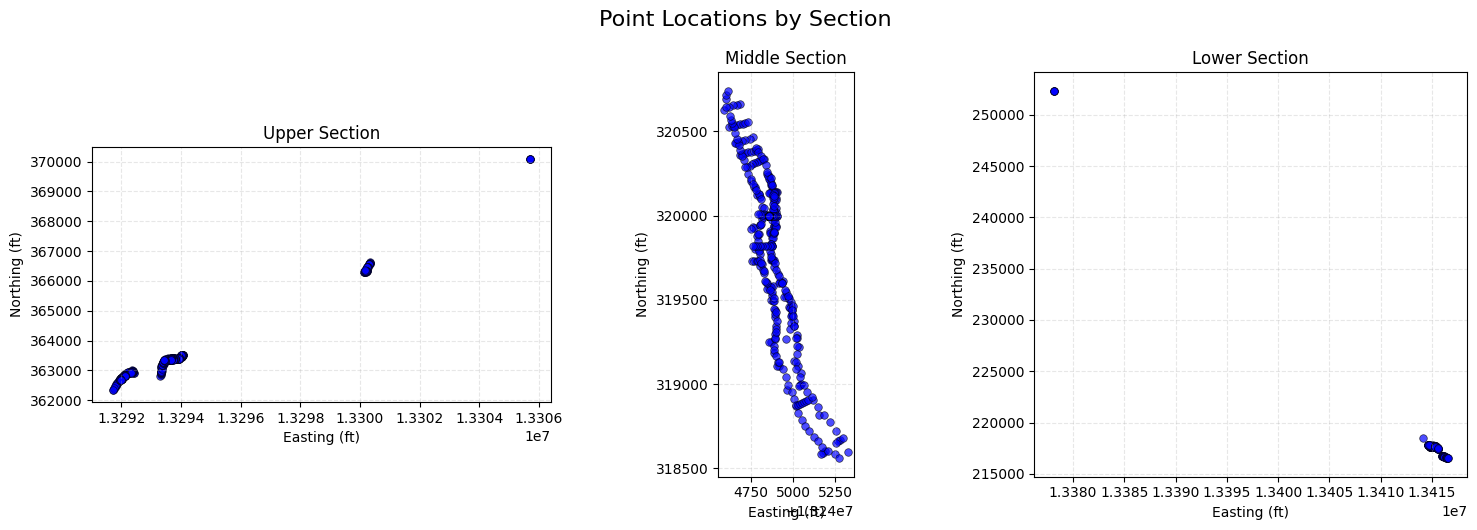

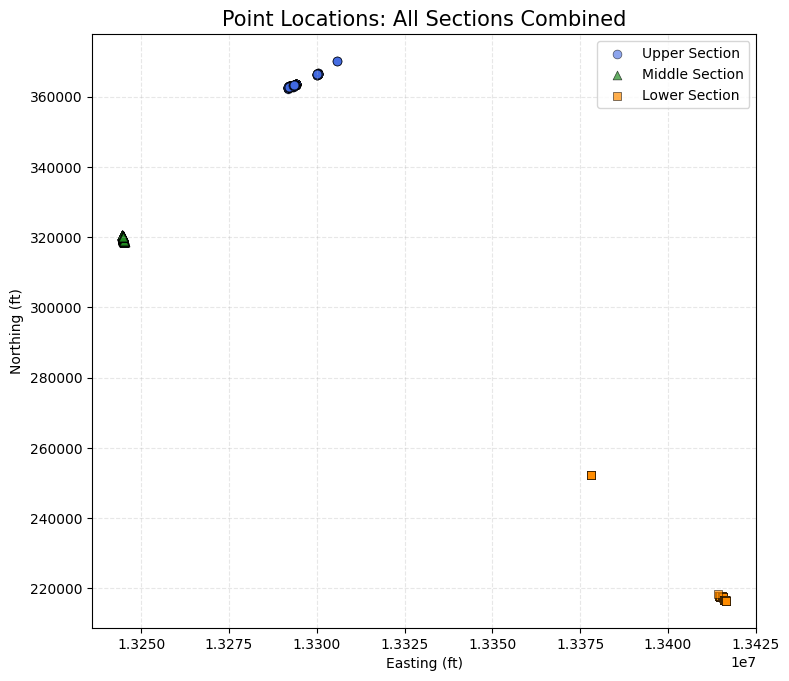

In [10]:
### 7) Visualize the data GeoJSONs to ensure all sorting happened properly
# These GeoJSONs are written from the in-memory trimmed frames in the cell above.
# Re-run that cell (and the trim cell) if the point counts below do not match the trim output.

# Import the GeoJSON files
df_Upper = gpd.read_file("mapping/data_Upper.geojson")
df_Middle = gpd.read_file("mapping/data_Middle.geojson")
df_Lower = gpd.read_file("mapping/data_Lower.geojson")

# Create a figure with subplots for each section
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Simple geospatial plot: just show point locations for each section

section_info = [
    (df_Upper, "Upper Section", 0),
    (df_Middle, "Middle Section", 1),
    (df_Lower, "Lower Section", 2)
]

for gdf, title, idx in section_info:
    ax = axes[idx]
    gdf.plot(
        ax=ax,
        marker='o',
        color='blue',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.7,
        markersize=30
    )
    ax.set_title(title)
    ax.set_xlabel('Easting (ft)')
    ax.set_ylabel('Northing (ft)')
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.suptitle("Point Locations by Section", fontsize=16, y=1.05)
plt.show()
       
# Plot all points from the three GeoJSON files on top of one another in a single plot

fig, ax = plt.subplots(figsize=(8, 8))

df_Upper.plot(
    ax=ax,
    marker='o',
    color='royalblue',
    edgecolor='k',
    linewidth=0.5,
    alpha=0.6,
    markersize=40,
    label='Upper Section'
)
df_Middle.plot(
    ax=ax,
    marker='^',
    color='forestgreen',
    edgecolor='k',
    linewidth=0.5,
    alpha=0.7,
    markersize=40,
    label='Middle Section'
)
df_Lower.plot(
    ax=ax,
    marker='s',
    color='darkorange',
    edgecolor='k',
    linewidth=0.5,
    alpha=0.7,
    markersize=40,
    label='Lower Section'
)

ax.set_title("Point Locations: All Sections Combined", fontsize=15)
ax.set_xlabel('Easting (ft)')
ax.set_ylabel('Northing (ft)')
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [11]:
### Make the river stem a single object
# the clipped centerline is a branched network (main river + tributaries + island
# loops), and shapely's project() on a disconnected MultiLineString accumulates part lengths in
# arbitrary order, which corrupts downstream distances. 
# To fix it, build_main_stem() below merges the network into ONE continuous
# LineString: it starts from the branch nearest to the most data points and extends through
# junctions, preferring branches that carry data points (tie-break: longer branch). All
# projections (sign, along-line distance) are then done against this single main stem.

target_crs = "ESRI:102690"

# Load the full centerline once and convert to the working CRS (State Plane MI South, feet)
centerline_full = gpd.read_file("mapping/Huron_RiverSystem.geojson")
print(f"Centerline loaded: {len(centerline_full)} features, CRS {centerline_full.crs}")
centerline_full = centerline_full.to_crs(target_crs)

def build_main_stem(line_union, points, tol=1.0):
    """Merge a (possibly branched) centerline network into a single continuous LineString.
    Starts from the merged part nearest to the most data points, then extends the chain through
    junctions in both directions, preferring the branch with the most data points
    (tie-break: longer branch). `tol` is the snapping tolerance (ft) for matching endpoints."""
    merged = linemerge(line_union) if line_union.geom_type == 'MultiLineString' else line_union
    if merged.geom_type == 'LineString':
        return merged
    parts = list(merged.geoms)
    
    # Count how many data points are nearest to each part
    counts = [0] * len(parts)
    for pt in points:
        if pt is None or pt.is_empty:
            continue
        dists = [pt.distance(p) for p in parts]
        counts[int(np.argmin(dists))] += 1
    
    def close(a, b):
        return abs(a[0] - b[0]) <= tol and abs(a[1] - b[1]) <= tol
    
    seed = int(np.argmax(counts))
    used = {seed}
    chain = [list(parts[seed].coords)]  # ordered list of coordinate lists
    
    def find_next(node):
        """Best unused part touching `node`: most data points, then longest."""
        best_key, best_j = None, None
        for j, p in enumerate(parts):
            if j in used:
                continue
            coords = list(p.coords)
            if close(coords[0], node) or close(coords[-1], node):
                key = (counts[j], p.length)
                if best_key is None or key > best_key:
                    best_key, best_j = key, j
        return best_j
    
    # Extend forward from the end of the chain
    while True:
        node = chain[-1][-1]
        j = find_next(node)
        if j is None:
            break
        used.add(j)
        coords = list(parts[j].coords)
        if close(coords[-1], node):
            coords.reverse()
        chain.append(coords)
    # Extend backward from the start of the chain
    while True:
        node = chain[0][0]
        j = find_next(node)
        if j is None:
            break
        used.add(j)
        coords = list(parts[j].coords)
        if close(coords[0], node):
            coords.reverse()
        chain.insert(0, coords)
    
    stem_coords = []
    for coords in chain:
        stem_coords.extend(coords[1:] if stem_coords else coords)
    return LineString(stem_coords)

Centerline loaded: 58 features, CRS EPSG:4269


In [12]:
### 6) Distance to Centerline + Downstream Distance Calculation
# Computes, for every point in mapping/data_{Section}.geojson:
#   - distance_to_centerline: signed distance to the river centerline
#       (negative = left of centerline, positive = right, same convention as the old gpModel cell)
#   - dist_along_centerline: absolute projected distance along the section's main-stem centerline.
#       Kept so the downstream reference point can be recovered from the data files alone
#       (reference = dist_along_centerline - downstream_dist for any row), e.g. for translating
#       model results back to coordinates via main_stem.interpolate(reference + downstream_dist)
#   - downstream_dist: dist_along_centerline minus the reference distance, where the reference
#       is the upstream-most projected point among points within 150 ft of the centerline
#       (matching the outlier filter applied in the gpModel notebooks)

def distances_to_line(points, line):
    """For each shapely Point, return (signed distance to `line`, projected distance along `line`).
    Signed distance is negative on the left of the line, positive on the right."""
    eps = 1.0  # feet on either side of the projected point, used to get the local tangent
    line_length = line.length
    signed = np.empty(len(points))
    along = np.empty(len(points))
    for i, point in enumerate(points):
        # Rows with missing Easting/Northing have no geometry; give them NaN
        # (they are then removed by the 150 ft outlier filter in the gpModel notebooks)
        if point is None or point.is_empty:
            signed[i] = np.nan
            along[i] = np.nan
            continue
        distance = point.distance(line)
        # Locate the nearest position along the line, then take a short local tangent
        d_along = line.project(point)
        p1 = line.interpolate(max(d_along - eps, 0))
        p2 = line.interpolate(min(d_along + eps, line_length))
        # Cross product of tangent vector with vector to the point determines the side
        cross = (p2.x - p1.x) * (point.y - p1.y) - (p2.y - p1.y) * (point.x - p1.x)
        signed[i] = -distance if cross > 0 else distance
        along[i] = d_along
    return signed, along

for section_name in sections:
    # Use the in-memory gdf that was just plotted; fall back to disk if this cell is run alone
    if 'section_gdfs' in globals() and section_name in section_gdfs:
        gdf = section_gdfs[section_name].copy()
    else:
        gdf = gpd.read_file(f"mapping/data_{section_name}.geojson")
    
    # Clip the centerline to this section's bounding box (500 ft buffer) to keep it small
    minx, miny, maxx, maxy = gdf.total_bounds
    bbox = box(minx - 500, miny - 500, maxx + 500, maxy + 500)
    section_centerline = centerline_full[centerline_full.geometry.intersects(bbox)]
    
    # Merge the branched network into one continuous main-stem LineString
    centerline_union = build_main_stem(section_centerline.geometry.union_all(), gdf.geometry.values)

    # Calculate signed distance to centerline and projected distance along it (one pass)
    signed_dists, along_dists = distances_to_line(gdf.geometry.values, centerline_union)
    gdf['distance_to_centerline'] = signed_dists
    gdf['dist_along_centerline'] = along_dists
    
    # Downstream distance: relative to the upstream-most projected point, considering only
    # points that will survive the 150 ft centerline-distance outlier filter in the gpModel
    # notebooks (so an off-river outlier can't shift the reference)
    valid_reference = np.abs(signed_dists) <= 150
    reference_distance = np.nanmin(along_dists[valid_reference])
    gdf['downstream_dist'] = along_dists - reference_distance
    
    print(f"\nSection: {section_name} ({len(gdf)} points, "
          f"{len(section_centerline)} centerline features in bbox, "
          f"main stem length {centerline_union.length:.0f} ft)")
    print(f"  Points with no geometry (NaN distance): {gdf['distance_to_centerline'].isna().sum()}")
    print(f"  Min distance:  {gdf['distance_to_centerline'].min():.2f} ft")
    print(f"  Max distance:  {gdf['distance_to_centerline'].max():.2f} ft")
    print(f"  Mean distance: {gdf['distance_to_centerline'].mean():.2f} ft")
    print(f"  Downstream reference distance: {reference_distance:.2f} ft")
    print(f"  Downstream range (within 150 ft of centerline): "
          f"{gdf.loc[valid_reference, 'downstream_dist'].min():.1f} to "
          f"{gdf.loc[valid_reference, 'downstream_dist'].max():.1f} ft")
    
    # Save the distance column back into the trimmed CSV (all original columns, no geometry)
    csv_path = os.path.join("sorted_data", f"complete_data_{section_name}.csv")
    pd.DataFrame(gdf.drop(columns='geometry')).to_csv(csv_path, index=False)
    print(f"  Updated {csv_path}")
    
    # Re-save the GeoJSON so it stays in sync with the CSV
    geojson_path = os.path.join("mapping", f"data_{section_name}.geojson")
    gdf.to_file(geojson_path, driver='GeoJSON')
    print(f"  Updated {geojson_path}")
    
    # Save the merged main-stem centerline (shapely LineString must be wrapped in a GeoDataFrame).
    # Used later to invert model coordinates, e.g. in modelVisualizations_Middle.ipynb:
    #   centerline = gpd.read_file("mapping/centerline_union_Middle.geojson")
    #   centerline_geom = centerline.geometry.iloc[0]
    centerline_path = os.path.join("mapping", f"centerline_union_{section_name}.geojson")
    gpd.GeoDataFrame(
        geometry=[centerline_union],
        crs=gdf.crs,
    ).to_file(centerline_path, driver='GeoJSON')
    print(f"  Updated {centerline_path}")


Section: Upper (326 points, 4 centerline features in bbox, main stem length 44906 ft)
  Points with no geometry (NaN distance): 0
  Min distance:  -76.81 ft
  Max distance:  36.34 ft
  Mean distance: -14.03 ft
  Downstream reference distance: 5757.01 ft
  Downstream range (within 150 ft of centerline): 0.0 to 25592.9 ft
  Updated sorted_data\complete_data_Upper.csv
  Updated mapping\data_Upper.geojson


Skipping field Collection Time: unsupported OGR type: 10


  Updated mapping\centerline_union_Upper.geojson

Section: Middle (797 points, 1 centerline features in bbox, main stem length 21598 ft)
  Points with no geometry (NaN distance): 3
  Min distance:  -95.47 ft
  Max distance:  81.60 ft
  Mean distance: -18.50 ft
  Downstream reference distance: 3781.94 ft
  Downstream range (within 150 ft of centerline): 0.0 to 2355.0 ft
  Updated sorted_data\complete_data_Middle.csv
  Updated mapping\data_Middle.geojson


Skipping field Collection Time: unsupported OGR type: 10


  Updated mapping\centerline_union_Middle.geojson

Section: Lower (165 points, 3 centerline features in bbox, main stem length 153501 ft)
  Points with no geometry (NaN distance): 0
  Min distance:  -191.90 ft
  Max distance:  67.30 ft
  Mean distance: -5.12 ft
  Downstream reference distance: 99519.24 ft
  Downstream range (within 150 ft of centerline): 0.0 to 3473.7 ft
  Updated sorted_data\complete_data_Lower.csv
  Updated mapping\data_Lower.geojson
  Updated mapping\centerline_union_Lower.geojson


In [13]:
### Trimming Data in Hindsight of the Model Performance
# The model performance struggled with data that was widely spread in space

# Trim the Upper site manually
# any points above 365000 ft Northing should be trimmed from the df and resave the csv
# Load the Upper site CSV
upper_csv_path = os.path.join("sorted_data", "complete_data_Upper.csv")
df_upper = pd.read_csv(upper_csv_path)

# Trim any points above 365000 ft Northing
# Assuming the northing column is named 'Northing' (adjust if its name is different)
trimmed_upper = df_upper[df_upper['Northing'] <= 365000].copy()

# Resave the CSV to the same location
trimmed_upper.to_csv(upper_csv_path, index=False)
print(f"Trimmed Upper site data (Northing <= 365000) and saved to {upper_csv_path}")

# Trim the Middle site manually
# any points above 321000 ft Northing should be trimmed from the df and resave the csv
# Load the Middle site CSV
middle_csv_path = os.path.join("sorted_data", "complete_data_Middle.csv")
df_middle = pd.read_csv(middle_csv_path)

# Trim any points above 321000 ft Northing
# Assuming the northing column is named 'Northing' (adjust if its name is different)
trimmed_middle = df_middle[df_middle['Northing'] <= 321000].copy()

# Resave the CSV to the same location
trimmed_middle.to_csv(middle_csv_path, index=False)
print(f"Trimmed Middle site data (Northing <= 321000) and saved to {middle_csv_path}")

# Trim the Lower site manually
# any points above 365000 ft Northing should be trimmed from the df and resave the csv
# Load the Lower site CSV
lower_csv_path = os.path.join("sorted_data", "complete_data_Lower.csv")
df_lower = pd.read_csv(lower_csv_path)

# Trim any points above 220000 ft Northing
# Assuming the northing column is named 'Northing' (adjust if its name is different)
trimmed_lower = df_lower[df_lower['Northing'] <= 220000].copy()

# Resave the CSV to the same location
trimmed_lower.to_csv(lower_csv_path, index=False)
print(f"Trimmed Lower site data (Northing <= 220000) and saved to {lower_csv_path}")

Trimmed Upper site data (Northing <= 365000) and saved to sorted_data\complete_data_Upper.csv
Trimmed Middle site data (Northing <= 321000) and saved to sorted_data\complete_data_Middle.csv
Trimmed Lower site data (Northing <= 220000) and saved to sorted_data\complete_data_Lower.csv


STREAMBED EXTENT AT MAXIMUM STAGE

Upper
--------------------------------------------------------------------------
  29 surveyed bank points on 15 of 21 transects
  dropped, transect has fewer than 4 in-water points to calibrate against: 0605-T03, 0812-T01, 0819-T01, 0819-T02, 0819-T03
  20 placed; bank elevation 861.6 to 866.1 ft
  left : 10 bank points; beyond them the edge is the survey plus 13.3 ft (measured)
  right: 10 bank points; beyond them the edge is the survey plus 8.1 ft (measured)
  1 continuous stretch(es) of river with data
  1 extra pass(es) to pull the edge outside every point on the ground
  width 23 to 90 ft (median 68)
  CHECK: 0 of 286 survey points outside the polygon
  wrote mapping/channel_extent_Upper.geojson  (4.6 acres)
  wrote mapping/bank_lines_Upper.geojson

Middle
--------------------------------------------------------------------------
  21 surveyed bank points on 11 of 20 transects
  dropped, transect has fewer than 4 in-water points to calibrate aga

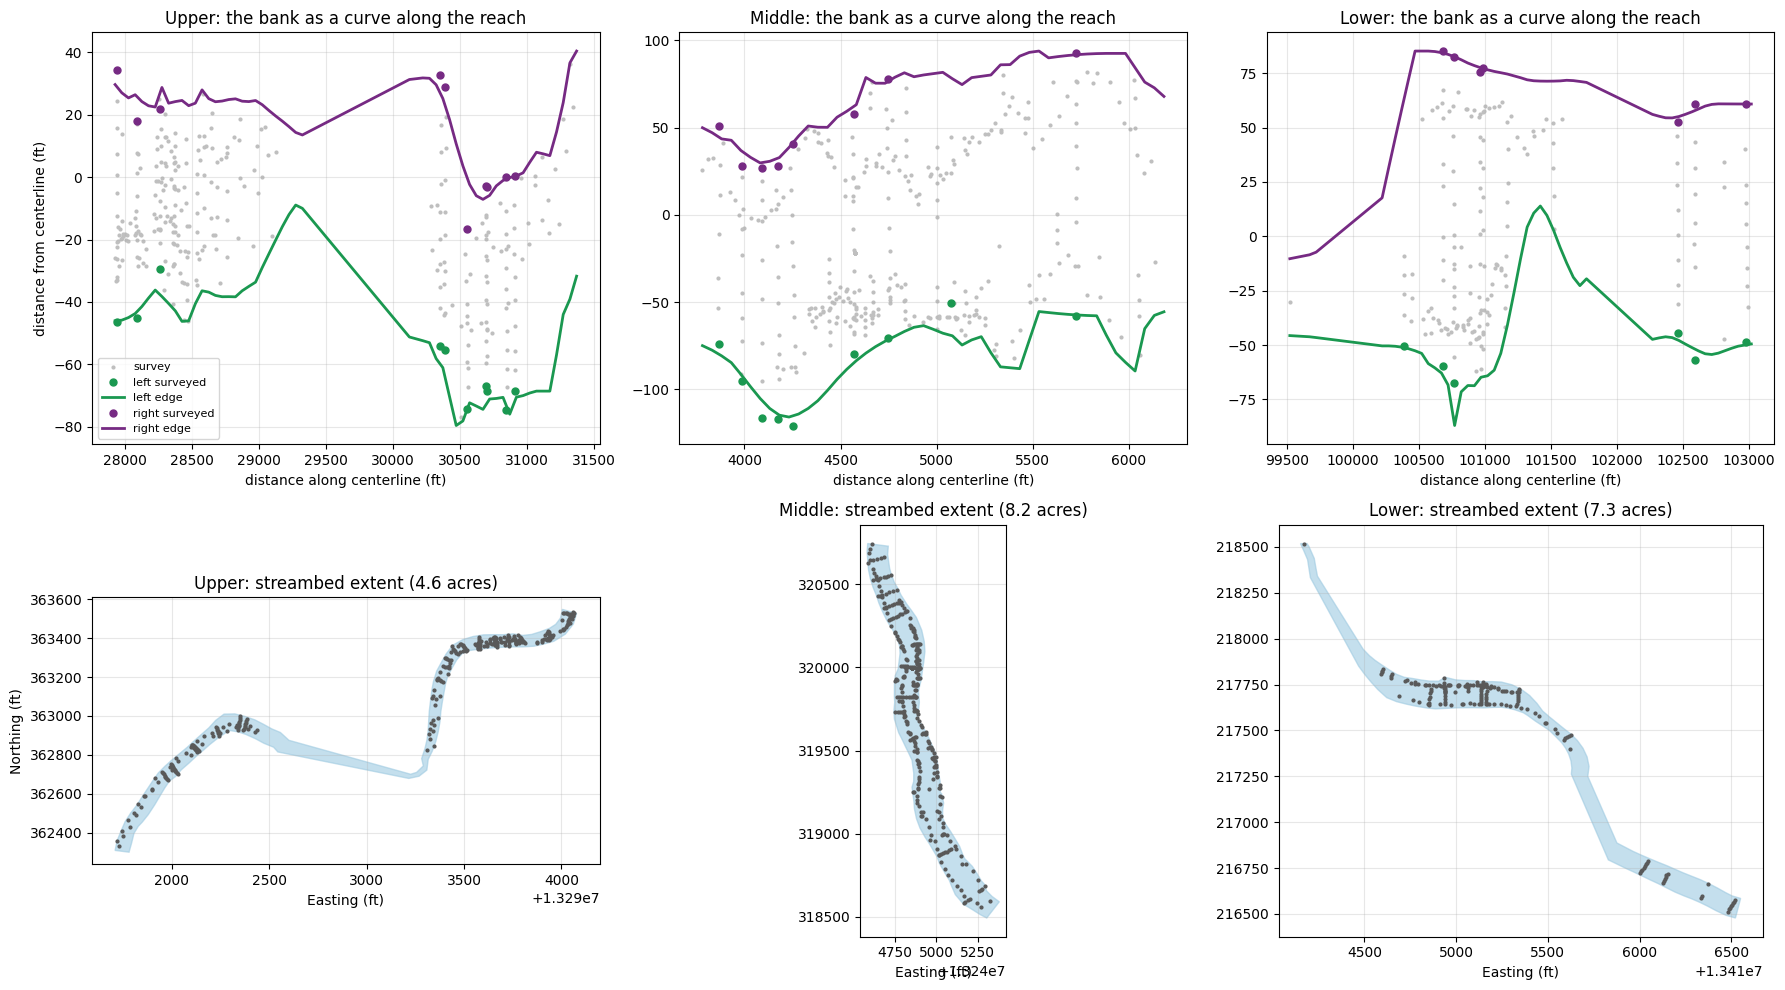


section  bank_points  stretches  median_width_ft  acres  points_outside
  Upper           20          1             68.1    4.6               0
 Middle           17          1            149.2    8.2               0
  Lower           13          1            108.4    7.3               0

USING THE POLYGON TO BOUND A MODEL
  extent = gpd.read_file('mapping/channel_extent_Middle.geojson').union_all()
  inside = gpd.GeoSeries(gpd.points_from_xy(grid_E, grid_N),
                         crs=target_crs).within(extent)
  Predict on the full grid, then drop the cells where `inside` is False.

WHAT THIS IS AND IS NOT
  It IS one stage: the streambed area available when the water is as high as it
  gets before leaving the channel, taken from bank points surveyed at that height.

  It is NOT a floodplain boundary, and it is NOT a measured edge everywhere. Where
  no bank point was surveyed, the edge is the outermost survey point plus a margin
  measured elsewhere in the same reach - a lower bou

In [14]:
### 8) Streambed extent: surveyed bank points -> continuous waterline -> polygon
# =============================================================================
# Add this as a new cell at the END of dataSorting.ipynb. It REPLACES the two
# earlier cells (the bank-waterline cell and the complete-bank-lines cell).
# It adds no columns to any table.
#
# WRITES, per section:
#   mapping/channel_extent_{Section}.geojson   the polygon - this is the output
#   mapping/bank_lines_{Section}.geojson       the two edges, for checking
#
# NEW IMPORT (everything else is already in cell 0)
#   from shapely.geometry import Polygon
#
# SELF-CONTAINED: the reach-frame conversion is defined below, so this cell needs no
# other project file. If you also keep reachframe.py, the sign convention in the two
# must match - the assertion under _to_map_frame catches a flip in this copy.
#
# ---------------------------------------------------------------------------
# HOW IT WORKS, IN FOUR STEPS
#
#   1. FIND THE BANK. Rows whose "Point Notes" name the bank are direct survey
#      points at the water's maximum extent. They carry no depth or velocity, so
#      section 4 drops them - this cell reads them from `complete_data`.
#
#   2. PUT EACH ONE ON THE REACH'S OWN SCALE. Along a transect,
#      distance_to_centerline changes in a straight line with position. Fitting
#      that line from the transect's in-water points and reading the bank point
#      off it gives its offset exactly (R-squared 0.99997 or better), using the
#      columns section 6 already wrote and recomputing no geometry.
#
#   3. TURN EACH BANK INTO A CURVE ALONG THE REACH. A bank described as "offset
#      from the centerline at each distance downstream" is a 1-D series, so the
#      gaps between transects are filled by interpolation rather than geometry.
#      Where no bank point was surveyed, the curve follows the outermost survey
#      point pushed outward by a margin - and that margin is measured, as the
#      median gap between the two where both exist.
#
#   4. CLOSE THE TWO CURVES INTO A POLYGON and check that every survey point
#      falls inside it. Any that do not push the nearby edge outward, and the
#      polygon is rebuilt until none are left.
#
# WHY IT IS ONE CELL
#   Steps 2 and 3 both work in (distance downstream, offset from centerline).
#   Writing the bank out as map coordinates in between and reading it back would
#   mean recovering those numbers through the curvilinear frame, which loses a
#   few feet on Upper and Lower and about fifteen on Middle. Keeping it in one
#   cell keeps the exact values.
# =============================================================================

from shapely.geometry import Polygon


# ------------ reach frame: (station, offset) -> (Easting, Northing) ----------
# One function decides which way a positive offset points, and one assertion pins
# it. Getting this backwards mirrors every map left-for-right, which is a mistake
# that has already happened once in this project and is invisible in the output.
_EPS_FT = 1.0          # spacing used to measure the centerline's direction


def _to_map_frame(line, station, offset):
    """Turn distance along the centerline and signed offset into map coordinates.

    Positive offset is to the RIGHT of the downstream direction, matching the sign
    of distance_to_centerline from section 6. Check it by hand: a line heading east
    has direction (1, 0); rotating it -90 degrees gives (0, -1), which points south;
    south is on your right when you face east.
    """
    station = np.atleast_1d(np.asarray(station, dtype=float))
    offset = np.atleast_1d(np.asarray(offset, dtype=float))
    length = line.length
    clipped = np.clip(station, 0.0, length)
    east = np.empty(clipped.shape)
    north = np.empty(clipped.shape)
    for i, sv in enumerate(clipped.ravel()):
        here = line.interpolate(float(sv))
        back = line.interpolate(max(float(sv) - _EPS_FT, 0.0))
        ahead = line.interpolate(min(float(sv) + _EPS_FT, length))
        dx, dy = ahead.x - back.x, ahead.y - back.y
        d = np.hypot(dx, dy)
        if d < 1e-12:
            dx, dy, d = 1.0, 0.0, 1.0
        tx, ty = dx / d, dy / d
        nx, ny = ty, -tx                      # rotate -90 degrees -> right of travel
        j = np.unravel_index(i, clipped.shape)
        east[j] = here.x + nx * offset.ravel()[i]
        north[j] = here.y + ny * offset.ravel()[i]
    return east, north


# known-answer check: a point at +10 offset from an east-flowing centerline is on
# river-right, which is SOUTH, so its northing must come out near -10.
_chk_e, _chk_n = _to_map_frame(LineString([(0.0, 0.0), (100.0, 0.0)]), [50.0], [10.0])
assert abs(_chk_e[0] - 50.0) < 1e-6 and _chk_n[0] < -9.99, (
    'REACH FRAME SIGN IS BACKWARDS: a positive offset must put the point on '
    'river-right (south of an east-flowing centerline). Every map from this cell '
    f'would be mirrored. Got easting {_chk_e[0]:.3f}, northing {_chk_n[0]:.3f}.')

# ------------------------------ SETTINGS -------------------------------------
SECTIONS       = ['Upper', 'Middle', 'Lower']

# Wordings in "Point Notes" that mark a surveyed point at the bank. Typed by
# hand, so the match ignores capitalisation and any extra or missing spaces.
# Add a wording here in lower case; nothing else needs to change.
BANK_NOTES     = ['bank height', 'edge of bank']

MIN_WET_POINTS = 4       # in-water points a transect needs before it can place a bank point
CALIB_LIMIT_FT = 150.0   # in-water points further off the centerline than this are
                         # not used to calibrate a transect (they distort the fit)
OUTSIDE_TOL_FT = 1.0     # a bank point may sit this far inside the in-water survey
                         # on its own side before it is rejected as a bad note

GRID_FT        = 50.0    # spacing of the stations the curve is defined at
BIN_FT         = 100.0   # length of reach each survey-edge sample summarises
WINDOW_FT      = 200.0   # a station counts as surveyed if data lies this close
BANK_REACH_FT  = 400.0   # how far along the reach a surveyed bank point is trusted
SMOOTH_FT      = 300.0   # moving-average length applied to the curve
SAFETY_FT      = 2.0     # keep the edge at least this far outside the survey
MIN_WIDTH_FT   = 10.0    # never let the two edges meet
MAX_GAP_FT     = 800.0   # break the polygon across a stretch with no data at all
MAX_PASSES     = 12      # attempts to pull the edge outside every point on the ground

os.makedirs('mapping', exist_ok=True)
print('=' * 74)
print('STREAMBED EXTENT AT MAXIMUM STAGE')
print('=' * 74)

fig, axgrid = plt.subplots(2, len(SECTIONS), figsize=(6 * len(SECTIONS), 10))
axgrid = np.atleast_2d(axgrid)
extent_summary = []

for ax, ax2, section_name in zip(axgrid[0], axgrid[1], SECTIONS):
    print(f'\n{section_name}')
    print('-' * 74)

    centerline = gpd.read_file(
        f'mapping/centerline_union_{section_name}.geojson').geometry.iloc[0]

    # =========================================================================
    # 1. the data, and the surveyed bank points
    # =========================================================================
    wet = pd.read_csv(f'sorted_data/complete_data_{section_name}.csv')
    wet = wet.dropna(subset=['Easting', 'Northing',
                             'dist_along_centerline', 'distance_to_centerline'])
    wet['day'] = pd.to_datetime(wet['Collection Date'], format='mixed').dt.date.astype(str)
    s_water = wet['dist_along_centerline'].values.astype(float)
    n_water = wet['distance_to_centerline'].values.astype(float)

    tidy_note = (complete_data['Point Notes'].astype(str).str.lower()
                 .str.replace(r'\s+', ' ', regex=True).str.strip())
    is_bank = np.zeros(len(complete_data), dtype=bool)
    for wording in BANK_NOTES:
        is_bank |= tidy_note.str.contains(wording, regex=False).values

    bank = complete_data[
        (complete_data['Section'] == section_name) & is_bank
    ].dropna(subset=['Easting', 'Northing', 'Elevation', 'Transect ID']).copy()
    bank = bank.drop_duplicates(subset=['Transect ID', 'Easting', 'Northing'])
    bank['day'] = pd.to_datetime(bank['Collection Date'], format='mixed').dt.date.astype(str)
    print(f'  {len(bank)} surveyed bank points on {bank["Transect ID"].nunique()} of '
          f'{wet["Transect ID"].nunique()} transects')

    # =========================================================================
    # 2. place each bank point on the reach's scale
    # =========================================================================
    placed, no_calib, rejected = [], [], []
    calib_pool = wet[wet['distance_to_centerline'].abs() <= CALIB_LIMIT_FT]

    for (tid, day), points in bank.groupby(['Transect ID', 'day']):
        t = calib_pool[(calib_pool['Transect ID'] == tid) & (calib_pool['day'] == day)]
        t = t.drop_duplicates(subset=['Easting', 'Northing'])
        if len(t) < MIN_WET_POINTS:
            no_calib.append(str(tid)); continue
        xy = t[['Easting', 'Northing']].values.astype(float)
        middle = xy.mean(0)
        direction = np.linalg.svd(xy - middle)[2][0]     # the line the transect runs along
        along_transect = (xy - middle) @ direction
        if np.ptp(along_transect) < 1.0:
            no_calib.append(str(tid)); continue
        n_t = t['distance_to_centerline'].values
        slope, intercept = np.polyfit(along_transect, n_t, 1)

        # The outermost in-water point at each END of the transect. Do not use the
        # sign of the offset to tell left from right: on a few transects the
        # centerline runs outside the channel and both banks come out negative.
        left_end, right_end = n_t.min(), n_t.max()

        proj = (points[['Easting', 'Northing']].values.astype(float) - middle) @ direction
        for (_, pt), offset in zip(points.iterrows(), slope * proj + intercept):
            past_left, past_right = left_end - offset, offset - right_end
            side = 'left' if past_left > past_right else 'right'
            if max(past_left, past_right) < -OUTSIDE_TOL_FT:
                rejected.append(f'{tid} ({-max(past_left, past_right):.0f} ft inside)')
                continue
            placed.append(dict(side=side,
                               station=float(t['dist_along_centerline'].median()),
                               offset=float(offset),
                               elev=float(pt['Elevation'])))

    if no_calib:
        print(f'  dropped, transect has fewer than {MIN_WET_POINTS} in-water points to '
              f'calibrate against: {", ".join(sorted(set(no_calib)))}')
    if rejected:
        print(f'  dropped, point lands inside the in-water survey on its own side: '
              f'{"; ".join(rejected)}')

    P = pd.DataFrame(placed)
    if P.empty:
        print('  SKIPPED: no bank points could be placed.')
        ax.set_title(f'{section_name}: no bank data')
        ax2.set_title(f'{section_name}: no bank data'); continue
    print(f'  {len(P)} placed; bank elevation {P["elev"].min():.1f} to '
          f'{P["elev"].max():.1f} ft')

    # =========================================================================
    # 3. turn each bank into a curve along the reach
    # =========================================================================
    grid = np.arange(s_water.min(), s_water.max() + GRID_FT, GRID_FT)

    # The edge of the survey. Collect the data into bins along the reach, take the
    # outermost point on each side in each bin, and draw a straight line between
    # bins. A rolling maximum would pick up and drop whole transects as it slid
    # along and come out as a staircase.
    cuts = np.arange(s_water.min(), s_water.max() + BIN_FT, BIN_FT)
    which = np.clip(np.digitize(s_water, cuts) - 1, 0, len(cuts) - 1)
    b_s, b_lo, b_hi = [], [], []
    for b in np.unique(which):
        m = which == b
        b_s.append(s_water[m].mean()); b_lo.append(n_water[m].min()); b_hi.append(n_water[m].max())
    survey_edge = {'left': np.interp(grid, b_s, b_lo),
                   'right': np.interp(grid, b_s, b_hi)}
    has_data = np.min(np.abs(grid[:, None] - s_water[None, :]), axis=1) <= WINDOW_FT

    curves = {}
    for side, outward in (('left', -1.0), ('right', +1.0)):
        pts_side = P[P['side'] == side].sort_values('station')
        edge = survey_edge[side]
        if len(pts_side) >= 2:
            bs = pts_side['station'].values
            bn = pts_side['offset'].values
            near = np.min(np.abs(grid[:, None] - bs[None, :]), axis=1) <= BANK_REACH_FT
            measured = np.where(near, np.interp(grid, bs, bn), np.nan)
            overlap = np.isfinite(measured)
            margin = max(float(np.median(outward * (measured[overlap] - edge[overlap]))), 0.0)
            print(f'  {side:5s}: {len(pts_side)} bank points; beyond them the edge is the '
                  f'survey plus {margin:.1f} ft (measured)')
        else:
            measured = np.full(grid.shape, np.nan)
            margin = 10.0
            print(f'  {side:5s}: too few bank points to measure a margin, using '
                  f'{margin:.1f} ft')

        curve = np.where(np.isfinite(measured), measured, edge + outward * margin)
        curve = np.convolve(curve, np.ones(int(round(SMOOTH_FT / GRID_FT))), 'same') / \
                np.convolve(np.ones_like(curve), np.ones(int(round(SMOOTH_FT / GRID_FT))), 'same')
        limit = edge + outward * SAFETY_FT                    # stay outside the survey
        curves[side] = np.where(outward * (limit - curve) > 0, limit, curve)

    narrow = (curves['right'] - curves['left']) < MIN_WIDTH_FT
    mid = 0.5 * (curves['left'] + curves['right'])
    curves['left'] = np.where(narrow, mid - MIN_WIDTH_FT / 2, curves['left'])
    curves['right'] = np.where(narrow, mid + MIN_WIDTH_FT / 2, curves['right'])

    # =========================================================================
    # 4. close into a polygon, and make it hold every survey point
    # =========================================================================
    gaps = np.flatnonzero(np.diff(grid[has_data]) > MAX_GAP_FT) + 1
    blocks = [b for b in np.split(np.flatnonzero(has_data), gaps) if len(b) >= 2]
    print(f'  {len(blocks)} continuous stretch(es) of river with data')

    survey_pts = gpd.GeoSeries(gpd.points_from_xy(wet['Easting'], wet['Northing']),
                               crs=target_crs)

    def build_shapes():
        edges, shapes = {}, []
        for side in ('left', 'right'):
            edges[side] = [LineString(np.column_stack(
                _to_map_frame(centerline, grid[idx], curves[side][idx]))) for idx in blocks]
        for k in range(len(blocks)):
            ring = np.vstack([np.array(edges['left'][k].coords),
                              np.array(edges['right'][k].coords)[::-1]])
            poly = Polygon(ring)
            shapes.append(poly if poly.is_valid else poly.buffer(0))
        return edges, shapes

    # Containment was enforced on the curve, in reach coordinates. That is not the
    # same as containment on the ground, because the reach frame distorts where the
    # centerline bends and the polygon edge is a straight chord between stations.
    # So build it, find what fell outside, push those stations out, and repeat.
    for attempt in range(MAX_PASSES):
        bank_edges, polys = build_shapes()
        extent = gpd.GeoSeries(polys, crs=target_crs).union_all()
        outside = ~survey_pts.within(extent.buffer(0.01))
        if not outside.any():
            break
        push = survey_pts[outside].distance(extent) + 0.5
        # take the LARGEST push each station needs, once - adding them up would let
        # neighbouring points compound and throw the edge far past anything measured
        need = {'left': np.zeros(grid.shape), 'right': np.zeros(grid.shape)}
        for ps, pn, dist in zip(s_water[outside.values], n_water[outside.values], push.values):
            i = int(np.argmin(np.abs(grid - ps)))
            side = 'left' if abs(pn - curves['left'][i]) <= abs(pn - curves['right'][i]) else 'right'
            near = np.abs(grid - ps) <= WINDOW_FT
            need[side][near] = np.maximum(need[side][near], dist)
        curves['left'] -= need['left']
        curves['right'] += need['right']
    if attempt:
        print(f'  {attempt} extra pass(es) to pull the edge outside every point on the ground')

    kept = np.concatenate(blocks)          # only the stations that make it into a polygon
    width = (curves['right'] - curves['left'])[kept]
    acres = sum(p.area for p in polys) / 43560.0
    print(f'  width {width.min():.0f} to {width.max():.0f} ft (median {np.median(width):.0f})')
    print(f'  CHECK: {int(outside.sum())} of {len(survey_pts)} survey points outside the '
          f'polygon' + ('' if not outside.any() else '   <-- investigate'))

    gpd.GeoDataFrame(
        [dict(section=section_name, stretch=k + 1,
              area_acres=round(p.area / 43560.0, 2),
              bank_elev_min_ft=round(float(P['elev'].min()), 2),
              bank_elev_max_ft=round(float(P['elev'].max()), 2),
              note='streambed at maximum stage; surveyed bank where available, '
                   'otherwise the survey edge plus the measured margin',
              geometry=p) for k, p in enumerate(polys)],
        crs=target_crs).to_file(f'mapping/channel_extent_{section_name}.geojson',
                                driver='GeoJSON')
    gpd.GeoDataFrame(
        [dict(section=section_name, bank=side, stretch=k + 1, geometry=g)
         for side in ('left', 'right') for k, g in enumerate(bank_edges[side])],
        crs=target_crs).to_file(f'mapping/bank_lines_{section_name}.geojson',
                                driver='GeoJSON')
    print(f'  wrote mapping/channel_extent_{section_name}.geojson  ({acres:.1f} acres)')
    print(f'  wrote mapping/bank_lines_{section_name}.geojson')

    extent_summary.append(dict(section=section_name, bank_points=len(P),
                               stretches=len(blocks),
                               median_width_ft=round(float(np.median(width)), 1),
                               acres=round(acres, 1),
                               points_outside=int(outside.sum())))

    # --- pictures ------------------------------------------------------------
    ax.scatter(s_water, n_water, s=4, c='0.75', label='survey')
    for side, colour in (('left', '#1A9850'), ('right', '#762A83')):
        q = P[P['side'] == side]
        ax.plot(q['station'], q['offset'], 'o', color=colour, ms=5,
                label=f'{side} surveyed')
        for k, idx in enumerate(blocks):
            ax.plot(grid[idx], curves[side][idx], '-', color=colour, lw=2,
                    label=f'{side} edge' if k == 0 else None)
    ax.set_title(f'{section_name}: the bank as a curve along the reach')
    ax.set_xlabel('distance along centerline (ft)'); ax.grid(alpha=0.3)

    for p in polys:
        xs, ys = p.exterior.xy
        ax2.fill(xs, ys, color='#9ECAE1', alpha=0.6, zorder=1)
    ax2.scatter(wet['Easting'], wet['Northing'], s=4, c='0.35', zorder=2)
    ax2.set_aspect('equal', adjustable='box')
    ax2.set_title(f'{section_name}: streambed extent ({acres:.1f} acres)')
    ax2.set_xlabel('Easting (ft)'); ax2.grid(alpha=0.3)

axgrid[0, 0].set_ylabel('distance from centerline (ft)')
axgrid[0, 0].legend(fontsize=8, loc='best')
axgrid[1, 0].set_ylabel('Northing (ft)')
plt.tight_layout(); plt.show()

print('\n' + '=' * 74)
print(pd.DataFrame(extent_summary).to_string(index=False))
print("""
USING THE POLYGON TO BOUND A MODEL
  extent = gpd.read_file('mapping/channel_extent_Middle.geojson').union_all()
  inside = gpd.GeoSeries(gpd.points_from_xy(grid_E, grid_N),
                         crs=target_crs).within(extent)
  Predict on the full grid, then drop the cells where `inside` is False.

WHAT THIS IS AND IS NOT
  It IS one stage: the streambed area available when the water is as high as it
  gets before leaving the channel, taken from bank points surveyed at that height.

  It is NOT a floodplain boundary, and it is NOT a measured edge everywhere. Where
  no bank point was surveyed, the edge is the outermost survey point plus a margin
  measured elsewhere in the same reach - a lower bound on the true width there.
  The printed margin is the size of that assumption.

  Where the survey skips a long stretch the polygon BREAKS rather than spanning
  it. The reach between stretches is not described, and predictions there are
  unbounded by this file.

  The curvilinear frame limits precision: a few feet on Upper and Lower, about
  fifteen on Middle, whose centerline bends more tightly than the channel is wide.
""")


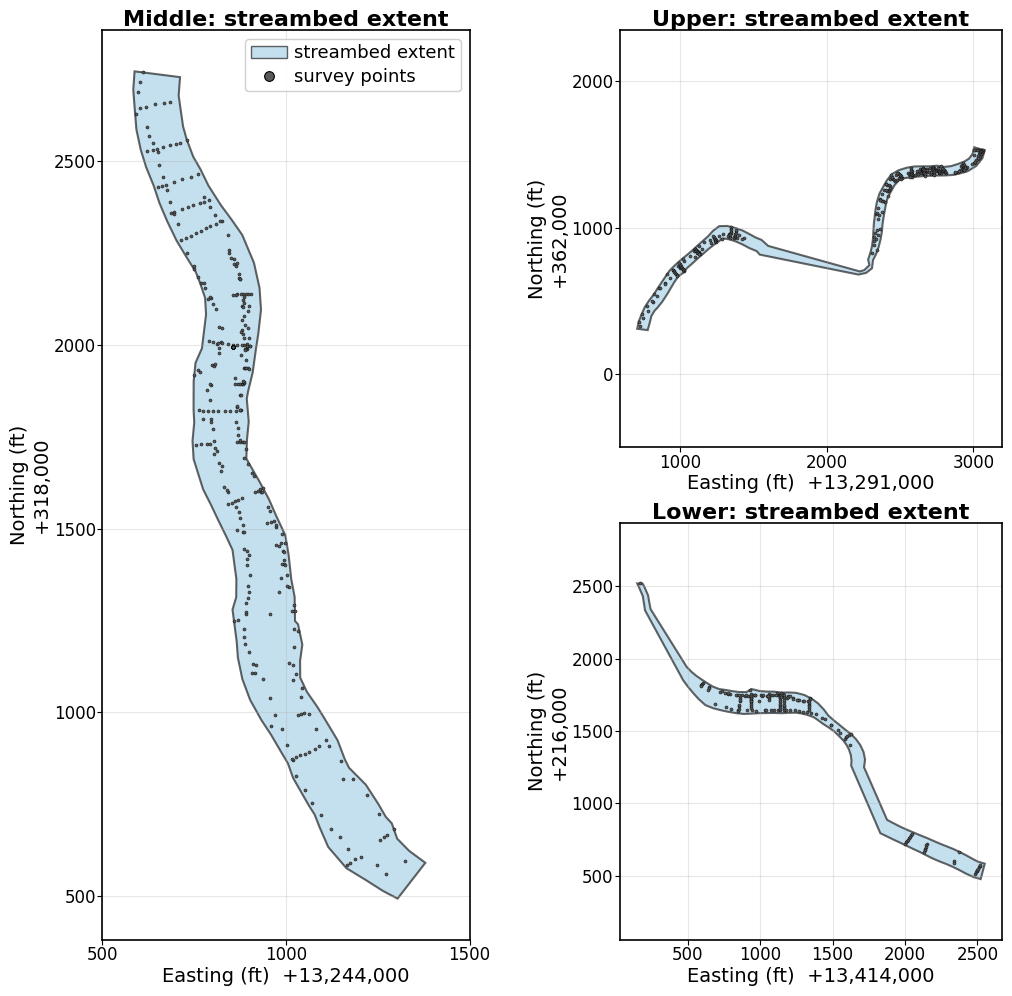

Square combined figure (10 × 10 in): Middle left; Upper top right; Lower bottom right.


In [15]:
### 9) Combined streambed extent figure (Middle large left, Upper/Lower stacked right)

# Reads the polygons written by cell 8 and the survey points, then draws the three
# map panels from the bottom row of that cell as one square figure:
#   Middle  - left half, slightly larger, full height
#   Upper   - top right
#   Lower   - bottom right
#
# Axis numbers are local feet from a round 1,000-ft origin so the State Plane
# values fit; the origin is in the axis label.
# Fonts are large relative to the maps: this figure is meant to be viewed small.

from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator

FILL = '#9ECAE1'
POINT = '0.35'
PANEL_NAMES = ('Middle', 'Upper', 'Lower')
TITLE_FONTSIZE = 16
LABEL_FONTSIZE = 14
TICK_FONTSIZE = 12
LEGEND_FONTSIZE = 13
BLACK = 'black'

def _round_offset(values, step=1000.0):
    return float(np.floor(np.min(values) / step) * step)

def _style_map_axes(ax, east, north):
    e0 = _round_offset(east)
    n0 = _round_offset(north)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=3, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=3, steps=[1, 2, 5, 10]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p, o=e0: f'{v - o:.0f}'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p, o=n0: f'{v - o:.0f}'))
    ax.set_xlabel(f'Easting (ft)  +{e0:,.0f}', fontsize=LABEL_FONTSIZE, labelpad=2, color=BLACK)
    ax.set_ylabel(f'Northing (ft)\n+{n0:,.0f}', fontsize=LABEL_FONTSIZE, labelpad=2, color=BLACK)
    ax.tick_params(labelsize=TICK_FONTSIZE, pad=1, colors=BLACK)
    ax.grid(True, alpha=0.3)
    # Set all spines to black
    for side in ax.spines:
        ax.spines[side].set_color(BLACK)
        ax.spines[side].set_linewidth(1.2)

fig = plt.figure(figsize=(10, 10), facecolor='white')
gs = GridSpec(
    2, 2, figure=fig,
    width_ratios=[1.2, 1.0],          # Middle slightly wider than half
    height_ratios=[1.0, 1.0],
    left=0.09, right=0.99, bottom=0.07, top=0.98,
    wspace=0.14, hspace=0.18,
)
axes = {
    'Middle': fig.add_subplot(gs[:, 0]),
    'Upper':  fig.add_subplot(gs[0, 1]),
    'Lower':  fig.add_subplot(gs[1, 1]),
}

for name in PANEL_NAMES:
    ax = axes[name]
    extent = gpd.read_file(f'mapping/channel_extent_{name}.geojson')
    wet = pd.read_csv(f'sorted_data/complete_data_{name}.csv')
    wet = wet.dropna(subset=['Easting', 'Northing'])

    for geom in extent.geometry:
        parts = geom.geoms if geom.geom_type == 'MultiPolygon' else [geom]
        for poly in parts:
            xs, ys = poly.exterior.xy
            ax.fill(xs, ys, color=FILL, alpha=0.6, zorder=1, edgecolor=BLACK, linewidth=1.5)
    ax.scatter(wet['Easting'], wet['Northing'], s=5, c=POINT, zorder=2, edgecolors=BLACK, linewidths=0.3)

    # Title in black, WITHOUT plot lettering
    ax.set_title(f'{name}: streambed extent',
                 fontsize=TITLE_FONTSIZE, fontweight='bold', pad=2, color=BLACK)
    bounds = extent.total_bounds
    _style_map_axes(ax,
                    np.array([bounds[0], bounds[2]]),
                    np.array([bounds[1], bounds[3]]))
    if name == 'Middle':
        # Keep this panel skinny so Upper/Lower Northing labels do not sit on it.
        e0 = _round_offset(np.array([bounds[0], bounds[2]]))
        ax.set_xlim(e0 + 500.0, e0 + 1500.0)
        ax.set_aspect('equal', adjustable='box', anchor='W')
    else:
        ax.set_aspect('equal', adjustable='datalim')

# Custom legend text color to black
legend = axes['Middle'].legend(
    handles=[
        Patch(facecolor=FILL, alpha=0.6, edgecolor=BLACK, linewidth=1.0, label='streambed extent'),
        Line2D([0], [0], marker='o', color='none', markerfacecolor=POINT,
               markeredgecolor=BLACK, markersize=7, markeredgewidth=0.8, label='survey points'),
    ],
    loc='upper right', fontsize=LEGEND_FONTSIZE, framealpha=0.92,
    borderpad=0.3, handletextpad=0.4, labelspacing=0.3,
)
for text in legend.get_texts():
    text.set_color(BLACK)

plt.show()
print('Square combined figure (10 × 10 in): Middle left; Upper top right; Lower bottom right.')
